<a href="https://colab.research.google.com/github/AlejoCNYT/aprMaqI_CEIA/blob/main/clase2/ejercicios/Solutions.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

## 1. Exploración de datos y limpieza

**Objetivo:** entender la calidad de los datos y qué variables ayudan a predecir si un usuario compra el producto anunciado.

**Hallazgos principales:**
- El dataset tiene 400 filas y 5 columnas, sin valores nulos ni filas duplicadas.
- **Balance de clases:** 64,25 % no compra (clase 0) y 35,75 % compra (clase 1). Es un desbalance moderado, por lo que la *accuracy* por sí sola puede engañar y conviene mirar también *precision*, *recall* y *F1*.
- **Clase más importante:** la clase 1 (compra). Perder a un comprador potencial (falso negativo) es más costoso que anunciarle a alguien que no compra.
- **Relevancia de variables:** `Age` tiene una correlación de 0,62 con la compra y `EstimatedSalary` de 0,36. `Gender` muestra una diferencia pequeña (37,7 % mujeres vs 33,7 % hombres), por lo que se descarta. `User ID` es un identificador único sin poder predictivo, por lo que también se descarta.
- Media y mediana de la edad son muy similares en ambas clases, por lo que no hay asimetría fuerte ni outliers relevantes.
- **Variables de entrada elegidas:** `Age` y `EstimatedSalary`.

(400, 5)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 400 entries, 0 to 399
Data columns (total 5 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   User ID          400 non-null    int64  
 1   Gender           400 non-null    object 
 2   Age              400 non-null    float64
 3   EstimatedSalary  400 non-null    float64
 4   Purchased        400 non-null    int64  
dtypes: float64(2), int64(2), object(1)
memory usage: 15.8+ KB
None
            User ID         Age  EstimatedSalary   Purchased
count  4.000000e+02  400.000000       400.000000  400.000000
mean   1.569154e+07   37.655000     69742.500000    0.357500
std    7.165832e+04   10.482877     34096.960282    0.479864
min    1.556669e+07   18.000000     15000.000000    0.000000
25%    1.562676e+07   29.750000     43000.000000    0.000000
50%    1.569434e+07   37.000000     70000.000000    0.000000
75%    1.575036e+07   46.000000     88000.000000    1.000000
max    1.

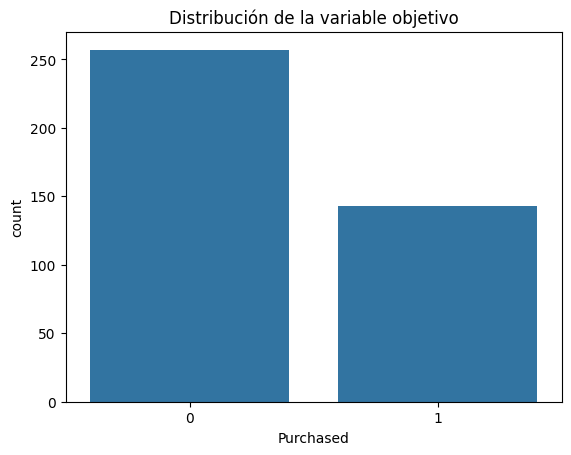

                 Age  EstimatedSalary
Purchased                            
0          32.793774     60544.747082
1          46.391608     86272.727273


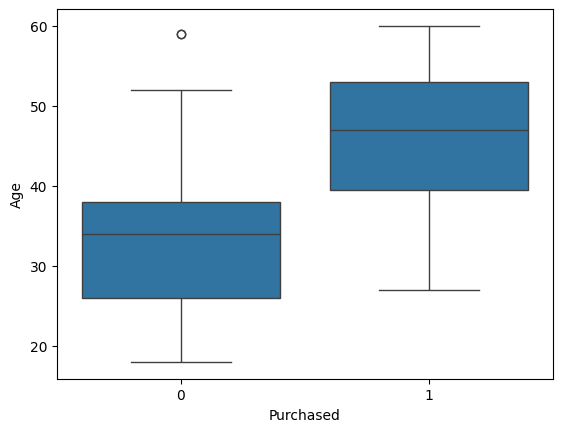

Gender
Female    0.377451
Male      0.336735
Name: Purchased, dtype: float64


In [17]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Carga de datos
df = pd.read_csv("Social_Network_Ads.csv")   # PISTA: función de pandas para leer archivos CSV

# 2. Estructura general
print(df.shape)
print(df.info())        # PISTA: muestra tipos de dato y nulos por columna
print(df.describe())        # PISTA: estadísticos descriptivos (media, min, max, cuartiles)

# 3. Calidad de datos
print("Nulos por columna:")
print(df.isnull().sum())  # PISTA: método que marca con True los valores faltantes

print("Filas duplicadas:", df.duplicated().sum())  # PISTA: método que detecta filas repetidas

# 4. Balance de clases
print(df["Purchased"].value_counts(normalize=True))   # PISTA: cuenta valores únicos; normalize=True da proporciones

sns.countplot(data=df, x="Purchased")             # PISTA: columna objetivo
plt.title("Distribución de la variable objetivo")
plt.show()

# 5. Relación de las variables con la compra
print(df.groupby("Purchased")[["Age", "EstimatedSalary"]].mean())
# PISTA: agrupá por la columna objetivo y calculá el promedio

sns.boxplot(data=df, x="Purchased", y="Age")   # PISTA: probá con "Age" y luego con "EstimatedSalary"
plt.show()

# 6. Variable categórica
print(df.groupby("Gender")["Purchased"].mean())  # PISTA: ¿qué proporción compra en cada género? Usá el promedio

In [18]:
# Correlación de cada variable numérica con el objetivo
print(df["Age"].corr(df["Purchased"]))               # PISTA: método de Series que calcula correlación con otra Series
print(df["EstimatedSalary"].corr(df["Purchased"]))

# ¿User ID tiene un valor distinto en cada fila?
print(df["User ID"].nunique() == len(df))               # PISTA: método que cuenta valores únicos (nunique)

# Mediana de edad por clase (más robusta que la media ante valores extremos)
print(df.groupby("Purchased")["Age"].median())          # PISTA: agregación "mediana"

# Gender es texto: los modelos necesitan números.
# PISTA: probá convertirla a 0/1 con un diccionario y .map()
df["Gender_num"] = df["Gender"].map({"Female": 0, "Male": 1})
print(df[["Gender", "Gender_num"]].head())

0.622454198884529
0.36208302580467927
True
Purchased
0    34.0
1    47.0
Name: Age, dtype: float64
   Gender  Gender_num
0    Male           1
1    Male           1
2  Female           0
3  Female           0
4    Male           1


### 2. Train/Validation Split & Feature Scaling Strategy

Separamos el dataset en conjuntos de *training* (75 %) y *validation* (25 %) usando **stratified sampling** sobre la *target variable* `Purchased`. Como las clases están moderadamente desbalanceadas (~64 % / 36 %), `stratify=y` garantiza que ambos conjuntos conserven la misma proporción de clases y que las métricas de evaluación sean comparables.

**Key Insights & Trade-offs**
- El *split* se realiza **antes** de cualquier transformación para evitar *data leakage*.
- El *scaler* se ajusta (`fit`) únicamente con *training data* y luego se aplica (`transform`) a *validation*.
- `EstimatedSalary` tiene una escala miles de veces mayor que `Age`; sin *feature scaling*, KNN (basado en distancias) quedaría dominado por el salario e ignoraría la edad.
- La regresión logística es menos sensible a la escala, pero el *scaling* mejora la convergencia y la interpretabilidad de los coeficientes.

In [19]:
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler


def split_and_scale(df, features, target, test_size=0.25, seed=42):
    """Split data with stratification and scale features without leakage.

    Args:
        df (pd.DataFrame): Source dataset.
        features (list[str]): Input column names.
        target (str): Target column name.
        test_size (float): Fraction of data used for validation.
        seed (int): Random seed for reproducibility.

    Returns:
        tuple: X_train_s, X_test_s, y_train, y_test, fitted scaler.
    """
    X, y = df[features], df[target]

    # Split first, then transform: prevents data leakage
    X_train, X_test, y_train, y_test = train_test_split(
        X, y, test_size=test_size, random_state=seed, stratify=y
    )

    scaler = StandardScaler()
    X_train_s = scaler.fit_transform(X_train)  # learn mean/std from train only
    X_test_s = scaler.transform(X_test)        # reuse train statistics

    return X_train_s, X_test_s, y_train, y_test, scaler


X_train_s, X_test_s, y_train, y_test, scaler = split_and_scale(
    df, ["Age", "EstimatedSalary"], "Purchased"
)

print("Train:", X_train_s.shape[0], "| Test:", X_test_s.shape[0])
print(y_train.value_counts(normalize=True))
print(y_test.value_counts(normalize=True))

Train: 300 | Test: 100
Purchased
0    0.643333
1    0.356667
Name: proportion, dtype: float64
Purchased
0    0.64
1    0.36
Name: proportion, dtype: float64


In [20]:
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier

# 1. Instanciar los modelos
log_reg = LogisticRegression(random_state=42)
knn = KNeighborsClassifier(n_neighbors=5)      # PISTA: usá k = 5

# 2. Entrenamiento (solo con datos de TRAIN escalados)
log_reg.fit(X_train_s, y_train)                        # PISTA: X de entrenamiento escalado
knn.fit(X_train_s, y_train)                          # PISTA: variable objetivo de entrenamiento

# 3. Predicciones de clase sobre VALIDACIÓN
y_pred_lr = log_reg.predict(X_test_s)                # PISTA: método que devuelve la clase (0 o 1)
y_pred_knn = knn.predict(X_test_s)                    # PISTA: X de validación escalado

# 4. Probabilidades de la regresión logística (para ROC en el Ejercicio 5)
y_proba_lr = log_reg.predict_proba(X_test_s)[:, 1]   # PISTA: columna de la clase positiva (1)

# 5. Verificación rápida
print("Primeras 10 predicciones LR :", y_pred_lr[:10])
print("Primeras 10 predicciones KNN:", y_pred_knn[:10])
print("Primeras 5 probabilidades LR:", y_proba_lr[:5].round(3))
print("Coeficientes LR (Age, Salary):", log_reg.coef_)

Primeras 10 predicciones LR : [0 0 0 0 1 0 0 0 1 0]
Primeras 10 predicciones KNN: [0 0 0 0 1 0 0 0 1 0]
Primeras 5 probabilidades LR: [0.354 0.216 0.368 0.066 0.758]
Coeficientes LR (Age, Salary): [[2.14393972 1.21072966]]


 KNN decide por vecinos y distancias mientras que en la regresión logística se combina linealmente las variables, aplica una sigmoide y tiene frontera lineal. Hubo que escalar porque EstimatedSalary, decenas de miles, dominaría la distancia frente a Age de 18-60.

In [21]:
from typing import Tuple

import numpy as np
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier


def train_baseline_models(
    X_train_s: np.ndarray,
    y_train: np.ndarray,
    k: int = 5,
    random_state: int = 42,
) -> Tuple[LogisticRegression, KNeighborsClassifier]:
    """Fit baseline Logistic Regression and KNN classifiers.

    Args:
        X_train_s: Scaled training features, shape (n_samples, n_features).
        y_train: Training labels, shape (n_samples,).
        k: Number of neighbors for KNN.
        random_state: Seed for reproducibility.

    Returns:
        Tuple with the fitted (log_reg, knn) models.
    """
    log_reg = LogisticRegression(random_state=random_state)
    knn = KNeighborsClassifier(n_neighbors=k)
    log_reg.fit(X_train_s, y_train)
    knn.fit(X_train_s, y_train)
    return log_reg, knn


log_reg, knn = train_baseline_models(X_train_s, y_train)

# Predictions on the validation set only (never on train, to avoid optimistic bias)
y_pred_lr = log_reg.predict(X_test_s)              # shape: (n_val,)
y_pred_knn = knn.predict(X_test_s)                 # shape: (n_val,)

# Class-1 probabilities: required for ROC curve and threshold tuning (Exercise 5)
y_proba_lr = log_reg.predict_proba(X_test_s)[:, 1]  # predict_proba shape: (n_val, 2)

print("LR coefficients (Age, Salary):", log_reg.coef_)  # shape: (1, 2)

LR coefficients (Age, Salary): [[2.14393972 1.21072966]]


Se compararon la Regresión Logística y KNN (k=5) sobre el conjunto de validación, usando Accuracy, Precision, Recall y F1-score. Dado que la clase de interés es "compra" (clase 1), el análisis prioriza Recall (usuarios compradores correctamente detectados) y F1 (balance entre Precision y Recall), y no solo Accuracy.

In [22]:
import pandas as pd
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score, confusion_matrix
)


def evaluate_model(y_true, y_pred, name: str) -> dict:
    """Compute classification metrics for a single model.

    Args:
        y_true: Ground-truth labels of the validation set.
        y_pred: Predicted class labels (not probabilities).
        name: Model name used as a label in the results table.

    Returns:
        dict: Model name and its Accuracy, Precision, Recall and F1
        (positive class = 1, i.e. "purchase").
    """
    return {
        "Model": name,
        "Accuracy": accuracy_score(y_true, y_pred),
        "Precision": precision_score(y_true, y_pred),
        "Recall": recall_score(y_true, y_pred),
        "F1": f1_score(y_true, y_pred),
    }


# 1. Comparative metrics table
results = pd.DataFrame([
    evaluate_model(y_test, y_pred_lr, "Logistic Regression"),
    evaluate_model(y_test, y_pred_knn, "KNN (k=5)"),
])
print(results.round(3))

# 2. Confusion matrices, layout: [[TN, FP], [FN, TP]]
cm_lr = confusion_matrix(y_test, y_pred_lr)
cm_knn = confusion_matrix(y_test, y_pred_knn)
print("Confusion matrix LR:\n", cm_lr)
print("Confusion matrix KNN:\n", cm_knn)

                 Model  Accuracy  Precision  Recall     F1
0  Logistic Regression      0.84      0.857   0.667  0.750
1            KNN (k=5)      0.91      0.886   0.861  0.873
Confusion matrix LR:
 [[60  4]
 [12 24]]
Confusion matrix KNN:
 [[60  4]
 [ 5 31]]


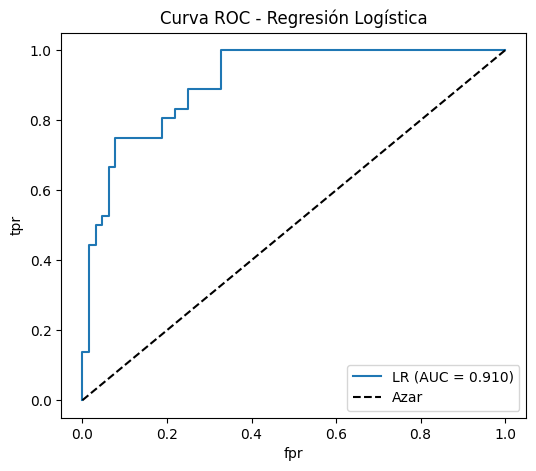

Umbral óptimo: 0.443


In [23]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import roc_curve, roc_auc_score

# 1. Probabilidad de la clase positiva (compra) con LR
y_proba_lr = log_reg.predict_proba(X_test_s)[:, 1]   # PISTA: método que devuelve probabilidades; columna de la clase 1

# 2. Curva ROC: devuelve FPR, TPR y umbrales
fpr, tpr, thresholds = roc_curve(y_test, y_proba_lr)  # PISTA: pasá las probabilidades, no las etiquetas

# 3. AUC
auc = roc_auc_score(y_test, y_proba_lr)               # PISTA: mismas probabilidades que el paso 2

# 4. Gráfico de la curva ROC
plt.figure(figsize=(6, 5))
plt.plot(fpr, tpr, label=f"LR (AUC = {auc:.3f})")
plt.plot([0, 1], [0, 1], "k--", label="Azar")
plt.xlabel("fpr")                              # PISTA: nombre del eje X (FPR)
plt.ylabel("tpr")                              # PISTA: nombre del eje Y (TPR)
plt.legend()
plt.title("Curva ROC - Regresión Logística")
plt.show()

# 5. Índice de Youden: máximo de (TPR - FPR)
youden = tpr - fpr
best_idx = np.argmax(youden)
best_threshold = thresholds[best_idx]               # PISTA: índice del máximo de Youden
print(f"Umbral óptimo: {best_threshold:.3f}")

# 6. Reclasificar con el nuevo umbral
y_pred_lr_opt = (y_proba_lr >= best_threshold).astype(int)  # PISTA: umbral óptimo calculado arriba

Dado que el costo de un falso positivo (mostrar un anuncio a quien no compra) es bajo y el costo de un falso negativo (perder un comprador) es alto, se elige un umbral bajo. Esto aumenta el Recall a costa de la Precision, priorizando capturar la mayor cantidad de compradores potenciales.

In [24]:
from sklearn.metrics import confusion_matrix

# Utilisation de la variable correcte 'best_threshold' définie à l'étape précédente
y_pred_lr_opt = (y_proba_lr >= best_threshold).astype(int)  # best_threshold: le seuil optimal de Youden

results_opt = pd.DataFrame([
    evaluate_model(y_test, y_pred_lr, "LR (umbral 0.5)"),
    evaluate_model(y_test, y_pred_lr_opt, "LR (umbral Youden)"),
])
print(results_opt.round(3))
print("Confusion matrix LR Youden:\n", confusion_matrix(y_test, y_pred_lr_opt))

                Model  Accuracy  Precision  Recall     F1
0     LR (umbral 0.5)      0.84      0.857   0.667  0.750
1  LR (umbral Youden)      0.86      0.844   0.750  0.794
Confusion matrix LR Youden:
 [[59  5]
 [ 9 27]]


Con el umbral de Youden, el Recall de la regresión logística pasa de 0.667 a 0.750, reduciendo los compradores no detectados de 12 a 9. A cambio, la Precision baja levemente (0.857 → 0.844). Dado que perder un comprador es más costoso que mostrar un anuncio de más, este trade-off es favorable, y el F1 también mejora, confirmando que el ajuste de umbral es una decisión útil y no solo un cambio de sesgo.

In [25]:
from sklearn.model_selection import GridSearchCV
from sklearn.neighbors import KNeighborsClassifier


def tune_knn(X_train, y_train, cv=5):
    """Search the best KNN hyperparameters using cross-validation.

    Args:
        X_train (np.ndarray): Scaled training features.
        y_train (np.ndarray): Training labels.
        cv (int): Number of cross-validation folds.

    Returns:
        GridSearchCV: Fitted search object with ``best_estimator_``
        and ``best_params_``.
    """
    param_grid = {
        "n_neighbors": list(range(1, 31)),
        "weights": ["uniform", "distance"],
        "p": [1, 2],  # 1 = Manhattan, 2 = Euclidean
    }
    base = KNeighborsClassifier(metric="minkowski")
    grid = GridSearchCV(base, param_grid, cv=cv, scoring="accuracy")
    grid.fit(X_train, y_train)  # Only training data: avoids leakage
    return grid


grid = tune_knn(X_train_s, y_train)
print("Best params:", grid.best_params_)
print("Best CV accuracy:", round(grid.best_score_, 3))

# Final evaluation on the untouched validation set
val_acc = grid.best_estimator_.score(X_test_s, y_test)
print("Validation accuracy:", round(val_acc, 3))

Best params: {'n_neighbors': 7, 'p': 2, 'weights': 'uniform'}
Best CV accuracy: 0.913
Validation accuracy: 0.92


La búsqueda de hiperparámetros optimiza una métrica sobre datos de entrenamiento mediante validación cruzada, pero no garantiza un mejor modelo por sí sola: un n_neighbors muy bajo puede obtener un buen score en CV y aun así sobreajustar. Por eso el conjunto de validación, que nunca participó en la búsqueda, es el que confirma si la mejora es real. Si el accuracy de validación de ese k=1 es similar al de k=5, la búsqueda no aportó una ganancia significativa y conviene preferir el modelo más simple y estable, considerando también la complejidad y la interpretabilidad.